# **A. Persiapan Dataset untuk Visualisasi**

## **1. Import Library**

Tahap awal untuk memuat library Python yang dibutuhkan dalam proses visualisasi data menggunakan Matplotlib dan Seaborn.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

## **2. Memuat Dataset yang Sudah Melalui Pre-processing**

In [2]:
from google.colab import drive
drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/2026GoogleColab_DataMining/Tugas2/Dataset/2318039_df_arabica_cleaned.csv'
df = pd.read_csv(file_path)

print('Dataset berhasil dibaca untuk visualisasi!')
print(f'Jumlah baris: {df.shape[0]} | Jumlah kolom: {df.shape[1]}')

Mounted at /content/drive
Dataset berhasil dibaca untuk visualisasi!
Jumlah baris: 207 | Jumlah kolom: 39


## **3. Pengecekkan Missing Values**

In [3]:
missing_values = df.isnull().sum()
print('--- Cek Nilai Kosong per Kolom ---')
print(missing_values[missing_values > 0])

print('\n--- Cek Jumlah Nilai Kosong pada Dataset ---')
if missing_values.sum() == 0:
    print('\nAman! Tidak ada nilai kosong (missing values) pada dataset ini.')
else:
    print(f'\nTotal nilai kosong pada dataset: {missing_values.sum()}')

--- Cek Nilai Kosong per Kolom ---
Farm Name            2
Lot Number           1
Mill                 3
Altitude             1
Region               2
Producer             1
Variety              6
Processing Method    5
dtype: int64

--- Cek Jumlah Nilai Kosong pada Dataset ---

Total nilai kosong pada dataset: 21


## **4. Mengisi Data yang Terjadi Missing Values**

In [4]:
df['Altitude'] = df['Altitude'].fillna(df['Altitude'].median())

categorical_cols = [
    'Farm Name',
    'Lot Number',
    'Mill',
    'Region',
    'Producer',
    'Variety',
    'Processing Method',
]
for col in categorical_cols:
  if col in df.columns:
    df[col] = df[col].fillna('Unknown')

print('--- Cek Ulang Setelah Dibersihkan ---')
print(f'Total nilai kosong sekarang: {df.isnull().sum().sum()}')

--- Cek Ulang Setelah Dibersihkan ---
Total nilai kosong sekarang: 0


# **B. Visualisasi Data Kualitas Kopi Arabika**

## **1. Visualisasi 1: Rata-rata Total Cup Points Berdasarkan Negara Asal (Bar Chart)**

Grafik batang ini menampilkan perbandingan rata-rata skor kualitas total (Total Cup Points) dari berbagai negara asal kopi. Tujuannya untuk mengetahui negara mana yang mendominasi kualitas tertinggi dalam dataset ini.

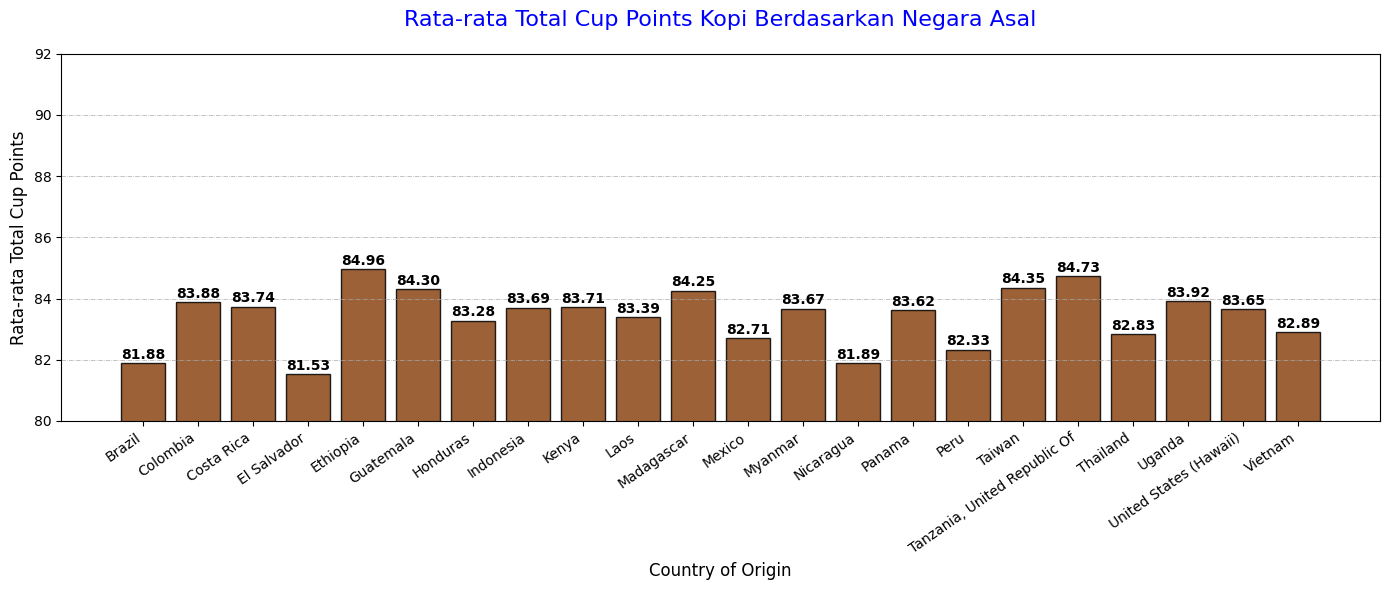

In [5]:
plt.figure(figsize=(14, 6))

country_points = (
    df.groupby('Country of Origin')['Total Cup Points'].mean().reset_index()
)

bars = plt.bar(
    country_points['Country of Origin'], country_points['Total Cup Points'],
    color='saddlebrown', edgecolor='black', alpha=0.85,
)

for bar in bars:
  yval = bar.get_height()
  plt.text(
      bar.get_x() + bar.get_width() / 2.0, yval + 0.05, f'{yval:.2f}', ha='center',
      va='bottom', fontsize=10, fontweight='bold',
  )

plt.title(
    'Rata-rata Total Cup Points Kopi Berdasarkan Negara Asal',
    loc='center', pad=20, fontsize=16, color='blue',
)
plt.xlabel('Country of Origin', fontsize=12)
plt.ylabel('Rata-rata Total Cup Points', fontsize=12)
plt.grid(color='darkgray', linestyle='-.', linewidth=0.5, axis='y')
plt.xticks(rotation=35, ha='right')
plt.ylim(ymin=80, ymax=92)

plt.tight_layout()
plt.show()

Pada visualisasi grafik batang di atas menunjukkan rata-rata skor kualitas kopi Arabika berdasarkan negara asalnya. Dari grafik tersebut, terdapat beberapa hal yang bisa dianalisis, yaitu:
- Tiga Negara dengan Rata-rata Skor Tertinggi
Berdasarkan grafik, Ethiopia menempati urutan pertama dengan rata-rata skor Total Cup Points sebesar 84,96. Selanjutnya, Tanzania (United Republic Of) berada di urutan kedua dengan skor 84,73, dan Taiwan berada di urutan ketiga dengan skor 84,35. Hal ini menunjukkan bahwa ketiga negara tersebut memiliki rata-rata skor kualitas kopi yang tinggi dibandingkan negara lainnya dalam dataset.
- Tiga Negara dengan Rata-rata Skor Terendah
Sementara itu, Nicaragua memiliki rata-rata skor sebesar 81,89, Brazil sebesar 81,88, dan El Salvador menempati posisi terakhir dengan skor 81,53. Walaupun berada di posisi terbawah, selisih skor antarnegara tidak terlalu jauh. Hal ini menunjukkan bahwa rata-rata skor kualitas kopi dari negara-negara yang ditampilkan masih berada dalam rentang yang cukup berdekatan.
- Posisi Indonesia dalam Dataset
Indonesia berada di urutan ke-10 dengan rata-rata skor Total Cup Points sebesar 83,69. Hasil ini menunjukkan bahwa rata-rata skor kualitas kopi Indonesia cukup tinggi dan berada di atas beberapa negara lainnya yang ditampilkan pada grafik. Dengan demikian, kopi Indonesia memiliki hasil penilaian yang cukup baik berdasarkan data yang dianalisis.

## **2. Visualisasi 2: Hubungan Ketinggian Lahan (Altitude) Terhadap Total Cup Points (Scatter Plot)**

Grafik sebar (scatter plot) ini digunakan untuk menganalisis apakah ketinggian tempat penanaman kopi (Altitude dalam mdpl) memiliki korelasi langsung terhadap peningkatan skor kualitas rasa kopi.

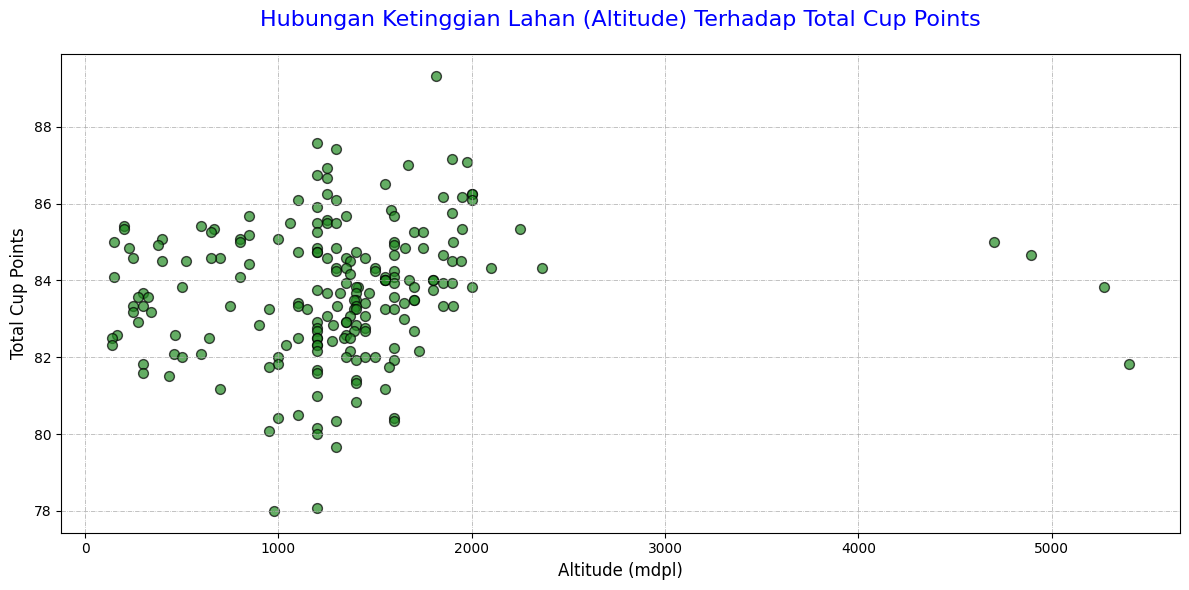

In [6]:
plt.figure(figsize=(12, 6))

plt.scatter(
    df['Altitude'],
    df['Total Cup Points'],
    color='forestgreen',
    alpha=0.7,
    edgecolors='black',
    s=50,
)

plt.title(
    'Hubungan Ketinggian Lahan (Altitude) Terhadap Total Cup Points',
    loc='center',
    pad=20,
    fontsize=16,
    color='blue',
)
plt.xlabel('Altitude (mdpl)', fontsize=12)
plt.ylabel('Total Cup Points', fontsize=12)
plt.grid(color='darkgray', linestyle='-.', linewidth=0.5)

plt.tight_layout()
plt.show()

Pada visualisasi grafik sebar (scatter plot) di atas menunjukkan hubungan antara ketinggian tempat penanaman kopi (Altitude dalam mdpl) dengan skor kualitas kopi berdasarkan Total Cup Points. Dari grafik tersebut, terdapat beberapa hal yang bisa dianalisis, yaitu:
- Sebaran Data Berdasarkan Ketinggian
Berdasarkan grafik, sebagian besar sampel kopi berada pada ketinggian sekitar 1.000 hingga 2.000 mdpl. Pada rentang tersebut, skor Total Cup Points paling banyak berada di kisaran 81 hingga 89. Hal ini menunjukkan bahwa sebagian besar sampel kopi dalam dataset berasal dari wilayah dataran tinggi dengan skor kualitas yang cukup beragam.
- Hubungan Ketinggian dengan Skor Kualitas Kopi
  Jika dilihat dari persebaran titik pada grafik, peningkatan ketinggian tempat tidak selalu diikuti dengan peningkatan skor kualitas kopi. Titik-titik yang ada cenderung menyebar dan tidak membentuk pola kenaikan yang jelas. Dengan demikian, ketinggian tempat saja belum cukup untuk menjelaskan tinggi atau rendahnya skor kualitas kopi, karena masih ada faktor lain yang dapat memengaruhinya, seperti varietas kopi dan proses pengolahan setelah panen.
- Adanya Data dengan Ketinggian Ekstrem
Pada grafik juga terlihat beberapa titik yang berada pada ketinggian di atas 4.000 hingga 5.000 mdpl. Titik-titik tersebut memiliki skor Total Cup Points sekitar 81 hingga 85. Hal ini menunjukkan bahwa sampel dengan ketinggian tersebut tidak selalu memiliki skor kualitas yang lebih tinggi dibandingkan sampel dari ketinggian lainnya. Namun, data tersebut juga perlu diperiksa kembali untuk memastikan bahwa nilai ketinggiannya sesuai dengan kondisi sebenarnya.

## **3. Visualisasi 3: Distribusi Frekuensi Total Cup Points Kopi Arabika (Histogram)**

Grafik histogram ini menampilkan sebaran atau frekuensi dari total nilai cupping. Tujuannya untuk melihat rentang nilai kualitas yang paling sering muncul dari keseluruhan sampel kopi.

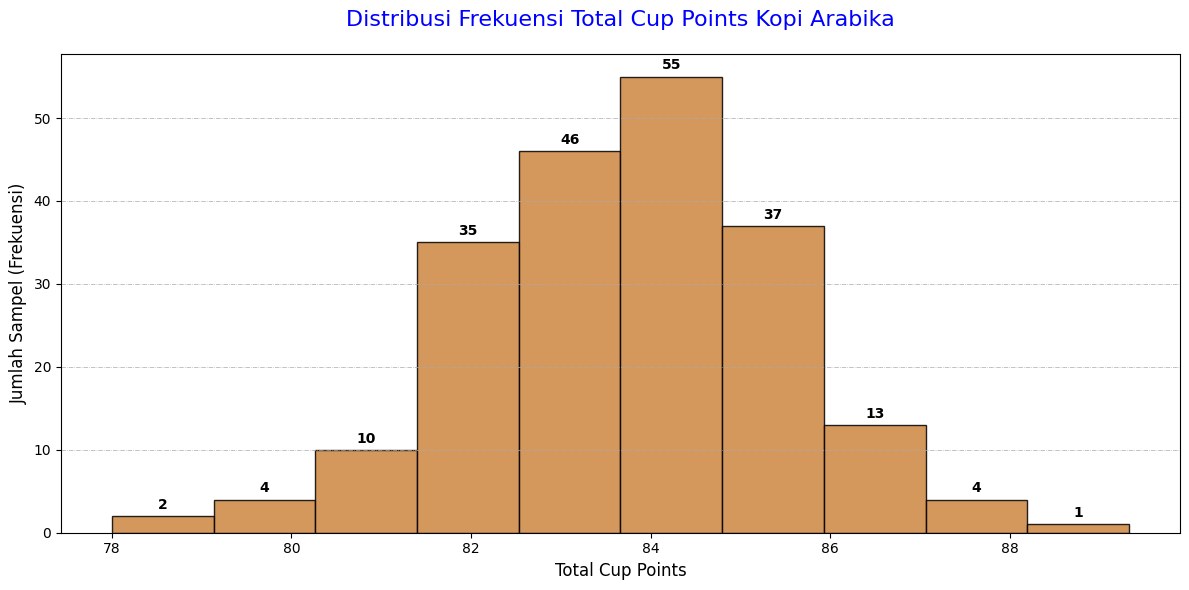

In [7]:
plt.figure(figsize=(12, 6))

n, bins, patches = plt.hist(
    df['Total Cup Points'],
    bins=10, color='peru', edgecolor='black', alpha=0.85,
)

for i in range(len(patches)):
  count = int(n[i])
  if count > 0:
    plt.text(
        patches[i].get_x() + patches[i].get_width() / 2.0,
        patches[i].get_height() + 0.5, str(count), ha='center',
        va='bottom', fontsize=10, fontweight='bold',
    )

plt.title(
    'Distribusi Frekuensi Total Cup Points Kopi Arabika',
    loc='center', pad=20, fontsize=16, color='blue',
)
plt.xlabel('Total Cup Points', fontsize=12)
plt.ylabel('Jumlah Sampel (Frekuensi)', fontsize=12)
plt.grid(color='darkgray', linestyle='-.', linewidth=0.5, axis='y')

plt.tight_layout()
plt.show()

Pada visualisasi grafik histogram di atas menunjukkan persebaran frekuensi skor kualitas kopi Arabika berdasarkan nilai Total Cup Points. Dari grafik tersebut, terdapat beberapa hal yang bisa dianalisis, yaitu:
- Rentang Nilai dengan Frekuensi Tertinggi
Berdasarkan grafik, frekuensi sampel terbanyak berada pada rentang nilai 83,7 hingga 84,8, dengan jumlah sebanyak 55 sampel. Hal ini menunjukkan bahwa sebagian besar sampel kopi memiliki skor kualitas yang berada di sekitar angka 84.
- Pola Persebaran Nilai
Jika dilihat dari bentuk histogramnya, sebagian besar data berkumpul pada rentang nilai tengah, yaitu sekitar 82,5 hingga 86,0, dengan total 138 sampel. Persebaran ini menunjukkan bahwa skor kualitas kopi dalam dataset cenderung terkonsentrasi pada rentang tersebut, meskipun belum tentu membentuk distribusi normal yang sempurna.
- Sampel dengan Nilai Terendah dan Tertinggi
Pada grafik juga terlihat bahwa jumlah sampel dengan skor di bawah 80 tergolong sedikit, yaitu sebanyak 6 sampel pada rentang 78 hingga 80,3. Sementara itu, sampel dengan skor di atas 87 hanya berjumlah 5 sampel pada rentang 87 hingga 89,3. Hal ini menunjukkan bahwa sampel kopi dalam dataset lebih banyak memiliki skor di rentang tengah dibandingkan skor yang sangat rendah maupun sangat tinggi.

## **4. Visualisasi 4: Perbandingan Rata-rata Skor Atribut Sensorik Utama (Bar Chart)**

Grafik ini merangkum skor rata-rata dari berbagai komponen penilaian rasa utama seperti Aroma, Flavor, Aftertaste, Acidity, dan Body, untuk melihat karakteristik sensorik apa yang paling menonjol pada kopi-kopi ini.

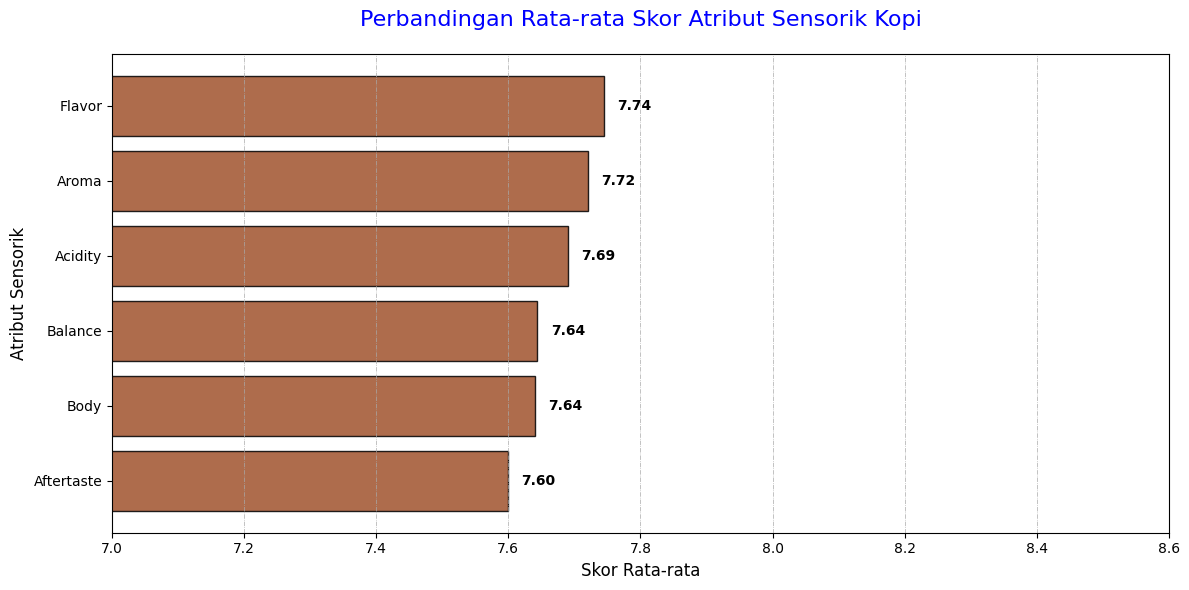

In [8]:
plt.figure(figsize=(12, 6))

flavor_attrs = ['Aroma', 'Flavor', 'Aftertaste', 'Acidity', 'Body', 'Balance']
mean_attrs = df[flavor_attrs].mean().sort_values()

bars = plt.barh(
    mean_attrs.index, mean_attrs.values, color='sienna', edgecolor='black', alpha=0.85,
)

for bar in bars:
  xval = bar.get_width()
  plt.text(
      xval + 0.02,
      bar.get_y() + bar.get_height() / 2.0,
      f'{xval:.2f}', ha='left', va='center', fontsize=10, fontweight='bold',
  )

plt.title(
    'Perbandingan Rata-rata Skor Atribut Sensorik Kopi',
    loc='center', pad=20, fontsize=16, color='blue',
)
plt.xlabel('Skor Rata-rata', fontsize=12)
plt.ylabel('Atribut Sensorik', fontsize=12)
plt.grid(color='darkgray', linestyle='-.', linewidth=0.5, axis='x')
plt.xlim(xmin=7.0, xmax=8.6)

plt.tight_layout()
plt.show()

Pada visualisasi diagram batang mendatar (horizontal bar chart) di atas menunjukkan perbandingan rata-rata skor dari beberapa atribut sensorik kopi Arabika. Dari grafik tersebut, terdapat beberapa hal yang bisa dianalisis, yaitu:
- Atribut Sensorik dengan Skor Tertinggi
Berdasarkan grafik, atribut Flavor memiliki rata-rata skor tertinggi sebesar 7,74, kemudian diikuti oleh Aroma dengan skor 7,72. Hal ini menunjukkan bahwa kedua atribut tersebut mendapatkan penilaian yang paling tinggi dibandingkan atribut sensorik lainnya dalam dataset.
- Perbandingan Skor Atribut Sensorik Lainnya
Atribut Acidity memperoleh rata-rata skor sebesar 7,69, sedangkan Balance dan Body sama-sama memiliki skor 7,64. Nilai tersebut menunjukkan bahwa perbedaan skor antaratribut tidak terlalu jauh, sehingga penilaian terhadap atribut sensorik kopi dalam dataset cenderung berada pada rentang yang berdekatan.
- Atribut Sensorik dengan Skor Terendah
Berdasarkan grafik, atribut Aftertaste memiliki rata-rata skor terendah, yaitu sebesar 7,60. Meskipun berada di posisi terakhir, selisih skornya dengan atribut lain cukup kecil. Hal ini menunjukkan bahwa skor Aftertaste masih relatif dekat dengan skor atribut sensorik lainnya, sehingga tidak terdapat perbedaan nilai yang terlalu mencolok pada hasil perbandingan tersebut.

# **Kesimpulan**

Berdasarkan keseluruhan visualisasi dan analisis data kualitas kopi Arabika yang telah dilakukan, berikut beberapa kesimpulannya, yaitu:
- Perbandingan Kualitas Kopi Berdasarkan Negara Asal
Berdasarkan hasil analisis, Ethiopia memiliki rata-rata skor Total Cup Points tertinggi, yaitu 84,96, sedangkan Indonesia berada di urutan ke-10 dengan skor 83,69. Hal ini menunjukkan bahwa kopi Indonesia memiliki skor kualitas yang cukup tinggi dan mampu bersaing dengan kopi dari negara lainnya dalam dataset.
- Hubungan Ketinggian dengan Kualitas Kopi
Sebagian besar sampel kopi ditanam pada ketinggian sekitar 1.000 hingga 2.000 mdpl. Namun, berdasarkan grafik sebar, ketinggian tempat tidak selalu diikuti dengan peningkatan skor kualitas kopi. Artinya, masih ada faktor lain, seperti varietas dan proses pengolahan, yang dapat memengaruhi hasil penilaian kualitas kopi.
- Persebaran Skor Kualitas Kopi
Berdasarkan grafik histogram, sebagian besar sampel kopi memiliki skor Total Cup Points di sekitar angka 84. Hal ini menunjukkan bahwa skor kualitas kopi dalam dataset cenderung terkumpul pada rentang nilai tengah, sedangkan sampel dengan skor yang sangat rendah maupun sangat tinggi jumlahnya lebih sedikit.
- Perbandingan Atribut Sensorik Kopi
Berdasarkan hasil analisis atribut sensorik, Flavor memperoleh rata-rata skor tertinggi sebesar 7,74, diikuti oleh Aroma sebesar 7,72. Sementara itu, Aftertaste memiliki skor terendah sebesar 7,60. Meskipun terdapat perbedaan skor, nilai antaratribut tersebut tidak terpaut jauh, sehingga penilaian sensorik kopi dalam dataset cenderung berada pada rentang yang berdekatan.